# MANUSCRIPT FIGURES
1. Violin plots (between-condition)
2. Significance matrix (within-condition)

In [21]:
# IMPORTS
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator
from matplotlib.ticker import FixedLocator
from matplotlib.patches import Patch
import matplotlib.pyplot as plt


# ============================================================
# GENERAL HELPERS
# ============================================================

def p_to_stars(p):
    if pd.isna(p):
        return ""
    if p < 0.001:
        return "***"
    if p < 0.01:
        return "**"
    if p < 0.05:
        return "*"
    return ""


def get_group_p(coupling, stage, condition):
    row = contrasts[
        (contrasts["coupling"] == coupling)
        & (contrasts["task_stage"] == stage)
        & (contrasts["condition"] == condition)
    ]
    return np.nan if row.empty else float(row.iloc[0]["p.value"])


def style_axes(ax, grid_axis="y"):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(0.8)
    ax.spines["bottom"].set_linewidth(0.8)

    if grid_axis:
        ax.grid(
            axis=grid_axis,
            linestyle="--",
            linewidth=0.6,
            alpha=0.25,
            zorder=0,
        )

    ax.tick_params(axis="both", labelsize=10)
    ax.yaxis.set_major_locator(MaxNLocator(nbins=6))


def get_y_padding(df, frac=0.08):
    y_min = df["lower_ci"].min()
    y_max = df["upper_ci"].max()
    yrange = y_max - y_min

    if yrange == 0:
        yrange = max(abs(y_max), 1) * 0.1

    return y_min, y_max, yrange, yrange * frac


def add_sig_bracket(ax, x1, x2, y, text, height):
    ax.plot(
        [x1, x1, x2, x2],
        [y, y + height, y + height, y],
        linewidth=1.1,
        clip_on=False,
    )
    ax.text(
        (x1 + x2) / 2,
        y + height,
        text,
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
    )


def add_half_violin(
    ax,
    values,
    position,
    color,
    side="left",
    width=0.28,
    alpha=0.30,
):
    """
    Draw one half of a violin distribution.
    """

    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]

    if len(values) < 2:
        return

    vp = ax.violinplot(
        [values],
        positions=[position],
        widths=width,
        showmeans=False,
        showmedians=False,
        showextrema=False,
    )

    body = vp["bodies"][0]

    body.set_facecolor(color)
    body.set_edgecolor(color)
    body.set_linewidth(1)
    body.set_alpha(alpha)

    path = body.get_paths()[0]
    vertices = path.vertices

    if side == "left":
        vertices[:, 0] = np.minimum(
            vertices[:, 0],
            position,
        )

    elif side == "right":
        vertices[:, 0] = np.maximum(
            vertices[:, 0],
            position,
        )


def add_individual_points(
    ax,
    values,
    position,
    color,
    side="right",
    jitter=0.060,
):
    """
    Add individual observations on the opposite half
    of the violin.
    """

    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]

    if len(values) == 0:
        return

    # Fixed seed gives reproducible jitter.
    rng = np.random.default_rng(12345)

    jitter_values = rng.uniform(
        0.025,
        jitter,
        len(values),
    )

    if side == "right":
        x_values = position + jitter_values

    else:
        x_values = position - jitter_values

    ax.scatter(
        x_values,
        values,
        s=POINT_SIZE,
        facecolor=color,
        edgecolor="white",
        linewidth=0.5,
        alpha=0.70,
        zorder=4,
    )


def get_group_p(
    coupling,
    stage,
    condition,
):
    """
    Retrieve Young-vs-Old p-value for a given
    coupling × stage × condition.
    """

    d = group_contrasts[
        (group_contrasts["coupling"] == coupling) &
        (group_contrasts["task_stage"] == stage) &
        (group_contrasts["condition"] == condition)
    ]

    if d.empty:
        return np.nan

    return d.iloc[0]["p.value"]

**1. VIOLIN PLOTS - old**

raw distributions deliberately faint and the EMMs visually dominant

In [ ]:
# ============================================================
# VIOLIN FIGURE
# GROUP × CONDITION — ALL COUPLINGS
#
# Visual emphasis:
# - faint half-violins = observed subject-level ERPAC
# - faint dots = individual participants
# - prominent open circles = EMMs
# - prominent error bars = 95% CI
# - significance brackets = Young vs Old emmeans contrasts
# ============================================================

# ============================================================
# PATHS
# ============================================================

LMM_DIR = Path(r"F:\# study 2\eeg_data\erpac\PCA\erpac_roi_tc\LMM")

EMM_FILE = LMM_DIR / "ERPAC_LMM_emmeans_for_plotting_no_ROI.csv"
GROUP_CONTRAST_FILE = LMM_DIR / "ERPAC_LMM_group_contrasts_no_ROI.csv"

FIG_DIR = LMM_DIR / "figures_no_ROI"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================
# DATA
# ============================================================

RAW_DF = pd.read_csv(LMM_DIR / "pca_erpac_LMM_all_tasks_ROI_averaged.csv")
VALUE_COL = "mean_erpac"

# ============================================================
# SETTINGS
# ============================================================

COUPLING_ORDER = ["theta_gamma", "alpha_gamma", "beta_gamma"]

CONDITION_ORDER = [
    "FTT",
    "DeCRAT_baseline",
    "DeCRAT_adaptation_early",
    "DeCRAT_adaptation_late",
]

STAGE_ORDER = ["plan", "go"]
GROUP_ORDER = ["Y", "O"]

CONDITION_LABELS = {
    "FTT": "FTT",
    "DeCRAT_baseline": "Baseline",
    "DeCRAT_adaptation_early": "Early\nadaptation",
    "DeCRAT_adaptation_late": "Late\nadaptation",
}

STAGE_LABELS = {"plan": "Planning", "go": "Execution"}
GROUP_LABELS = {"Y": "Young", "O": "Old"}

COUPLING_LABELS = {
    "theta_gamma": r"$\theta$–$\gamma$ ERPAC",
    "alpha_gamma": r"$\alpha$–$\gamma$ ERPAC",
    "beta_gamma": r"$\beta$–$\gamma$ ERPAC",
}

# Explicitly chosen for presentation clarity.
STAGE_COLORS = {"plan": "#2A6F97", "go": "#D97706"}
GROUP_COLORS = {"Y": "#2F80ED", "O": "#C44E52"}

DPI = 300

# ============================================================
# LOAD DATA
# ============================================================

emm = pd.read_csv(EMM_FILE)
contrasts = pd.read_csv(GROUP_CONTRAST_FILE)

VALUE_COL = "mean_erpac"      
SUB_COL = "sub"

# Your current "condition_contrasts" dataframe is actually
# the Young-vs-Old contrast within each condition.
group_contrasts = contrasts.copy()

# ============================================================
# PLOT SETTINGS
# ============================================================

GROUP_OFFSET = {
    "Y": -0.18,
    "O":  0.18,
}

VIOLIN_WIDTH = 0.28

# Raw-data appearance
RAW_VIOLIN_ALPHA = 0.12
RAW_POINT_ALPHA = 0.28
RAW_POINT_SIZE = 18
POINT_JITTER = 0.060

# Model-estimate appearance
EMM_SIZE = 85
EMM_LINEWIDTH = 2.5
CI_LINEWIDTH = 2.0
CI_CAPSIZE = 5


# ============================================================
# HELPERS
# ============================================================

def add_half_violin(
    ax,
    values,
    position,
    color,
    side="left",
    width=0.28,
    alpha=0.12,
):

    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]

    if len(values) < 2:
        return

    vp = ax.violinplot(
        [values],
        positions=[position],
        widths=width,
        showmeans=False,
        showmedians=False,
        showextrema=False,
    )

    body = vp["bodies"][0]

    body.set_facecolor(color)
    body.set_edgecolor(color)
    body.set_linewidth(0.8)
    body.set_alpha(alpha)

    vertices = body.get_paths()[0].vertices

    if side == "left":
        vertices[:, 0] = np.minimum(
            vertices[:, 0],
            position,
        )

    elif side == "right":
        vertices[:, 0] = np.maximum(
            vertices[:, 0],
            position,
        )


def add_individual_points(
    ax,
    values,
    position,
    color,
    side="right",
    jitter=0.060,
):

    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]

    if len(values) == 0:
        return

    rng = np.random.default_rng(12345)

    jitter_values = rng.uniform(
        0.025,
        jitter,
        len(values),
    )

    if side == "right":
        x_values = position + jitter_values
    else:
        x_values = position - jitter_values

    ax.scatter(
        x_values,
        values,
        s=RAW_POINT_SIZE,
        facecolor=color,
        edgecolor="none",
        alpha=RAW_POINT_ALPHA,
        zorder=2,
    )


def get_group_p(
    coupling,
    stage,
    condition,
):

    d = group_contrasts[
        (group_contrasts["coupling"] == coupling) &
        (group_contrasts["task_stage"] == stage) &
        (group_contrasts["condition"] == condition)
    ]

    if d.empty:
        return np.nan

    return d.iloc[0]["p.value"]


# ============================================================
# CHECK DATA LEVEL
# ============================================================

check = (
    RAW_DF
    .groupby(
        [
            "sub",
            "group",
            "coupling",
            "task_stage",
            "condition",
        ]
    )
    .size()
)

if check.max() > 1:
    print(
        "WARNING: Some subjects have more than one value "
        "per group × coupling × stage × condition."
    )

    print(
        check[check > 1]
        .sort_values(ascending=False)
        .head(20)
    )


# ============================================================
# MAIN LOOP — ALL COUPLINGS
# ============================================================

for coupling in emm["coupling"].dropna().unique():

    df_emm = emm[
        emm["coupling"] == coupling
    ].copy()

    df_raw = RAW_DF[
        RAW_DF["coupling"] == coupling
    ].copy()

    if df_emm.empty or df_raw.empty:
        continue


    # --------------------------------------------------------
    # Y-axis limits
    # --------------------------------------------------------

    raw_min = df_raw[VALUE_COL].min()
    raw_max = df_raw[VALUE_COL].max()

    ci_min = df_emm["lower_ci"].min()
    ci_max = df_emm["upper_ci"].max()

    y_min = np.nanmin([
        raw_min,
        ci_min,
    ])

    y_max = np.nanmax([
        raw_max,
        ci_max,
    ])

    yrange = y_max - y_min

    if not np.isfinite(yrange) or yrange == 0:
        yrange = 1

    pad = yrange * 0.08


    # ========================================================
    # FIGURE
    # ========================================================

    fig, axes = plt.subplots(
        1,
        len(STAGE_ORDER),
        figsize=(13.5, 5.8),
        sharey=True,
        constrained_layout=True,
    )

    axes = np.atleast_1d(axes)


    # ========================================================
    # STAGE PANELS
    # ========================================================

    for ax, stage in zip(
        axes,
        STAGE_ORDER,
    ):

        df_raw_stage = df_raw[
            df_raw["task_stage"] == stage
        ]

        df_emm_stage = df_emm[
            df_emm["task_stage"] == stage
        ]

        x = np.arange(
            len(CONDITION_ORDER)
        )

        positions = {
            group: x + GROUP_OFFSET[group]
            for group in GROUP_ORDER
        }

        emm_values = {
            group: {}
            for group in GROUP_ORDER
        }


        # ====================================================
        # RAW DISTRIBUTIONS + EMM
        # ====================================================

        for group in GROUP_ORDER:

            for i, condition in enumerate(
                CONDITION_ORDER
            ):

                pos = positions[group][i]


                # ------------------------------------------------
                # Observed subject-level values
                # ------------------------------------------------

                d_raw = df_raw_stage[
                    (df_raw_stage["group"] == group) &
                    (
                        df_raw_stage["condition"]
                        == condition
                    )
                ]

                values = (
                    d_raw[VALUE_COL]
                    .dropna()
                    .to_numpy()
                )


                # ------------------------------------------------
                # Raincloud orientation
                # ------------------------------------------------

                if group == "Y":
                    violin_side = "left"
                    point_side = "right"
                else:
                    violin_side = "right"
                    point_side = "left"


                # ------------------------------------------------
                # Faint violin
                # ------------------------------------------------

                add_half_violin(
                    ax,
                    values,
                    position=pos,
                    color=GROUP_COLORS[group],
                    side=violin_side,
                    width=VIOLIN_WIDTH,
                    alpha=RAW_VIOLIN_ALPHA,
                )


                # ------------------------------------------------
                # Faint individual observations
                # ------------------------------------------------

                add_individual_points(
                    ax,
                    values,
                    position=pos,
                    color=GROUP_COLORS[group],
                    side=point_side,
                    jitter=POINT_JITTER,
                )


                # ------------------------------------------------
                # EMM + 95% CI
                # ------------------------------------------------

                d_emm = df_emm_stage[
                    (df_emm_stage["group"] == group) &
                    (
                        df_emm_stage["condition"]
                        == condition
                    )
                ]

                if d_emm.empty:
                    continue

                row = d_emm.iloc[0]

                mean = row["emmean"]
                low = row["lower_ci"]
                high = row["upper_ci"]

                emm_values[group][condition] = {
                    "mean": mean,
                    "low": low,
                    "high": high,
                }


                # ------------------------------------------------
                # Prominent CI
                # ------------------------------------------------

                ax.errorbar(
                    pos,
                    mean,
                    yerr=np.array([
                        [mean - low],
                        [high - mean],
                    ]),
                    fmt="none",
                    ecolor=GROUP_COLORS[group],
                    elinewidth=CI_LINEWIDTH,
                    capsize=CI_CAPSIZE,
                    capthick=1.6,
                    zorder=7,
                )


                # ------------------------------------------------
                # Prominent EMM
                # ------------------------------------------------

                ax.scatter(
                    pos,
                    mean,
                    s=EMM_SIZE,
                    facecolor="white",
                    edgecolor=GROUP_COLORS[group],
                    linewidth=EMM_LINEWIDTH,
                    zorder=8,
                )


        # ====================================================
        # YOUNG VS OLD SIGNIFICANCE
        # ====================================================

        for i, condition in enumerate(
            CONDITION_ORDER
        ):

            p = get_group_p(
                coupling,
                stage,
                condition,
            )

            stars = p_to_stars(p)

            if not stars:
                continue

            if (
                condition not in emm_values["Y"]
                or
                condition not in emm_values["O"]
            ):
                continue


            raw_condition = df_raw_stage[
                df_raw_stage["condition"]
                == condition
            ][VALUE_COL]

            raw_top = (
                raw_condition.max()
                if not raw_condition.empty
                else -np.inf
            )

            ci_top = max(
                emm_values["Y"][condition]["high"],
                emm_values["O"][condition]["high"],
            )

            y_bracket = max(
                raw_top,
                ci_top,
            ) + pad * 0.30


            add_sig_bracket(
                ax,
                positions["Y"][i],
                positions["O"][i],
                y_bracket,
                stars,
                height=pad * 0.18,
            )


        # ====================================================
        # FORMATTING
        # ====================================================

        ax.set_title(
            STAGE_LABELS[stage],
            fontsize=14,
            fontweight="semibold",
            pad=12,
        )

        ax.set_xticks(x)

        ax.set_xticklabels(
            [
                CONDITION_LABELS[c]
                for c in CONDITION_ORDER
            ],
            fontsize=10,
        )

        ax.set_xlabel(
            "Condition",
            fontsize=11,
        )

        ax.set_ylabel(
            "ERPAC",
            fontsize=11,
        )

        style_axes(
            ax,
            grid_axis="y",
        )

        ax.set_ylim(
            y_min - pad * 0.5,
            y_max + pad * 1.8,
        )


    # ========================================================
    # LEGEND
    # ========================================================

    group_handles = [
        Patch(
            facecolor=GROUP_COLORS[group],
            edgecolor=GROUP_COLORS[group],
            alpha=0.25,
            label=GROUP_LABELS[group],
        )
        for group in GROUP_ORDER
    ]

    emm_handle = Line2D(
        [0],
        [0],
        marker="o",
        linestyle="none",
        markerfacecolor="white",
        markeredgecolor="black",
        markeredgewidth=2,
        markersize=8,
        # label="Estimated marginal mean ± 95% CI",
    )

    raw_handle = Line2D(
        [0],
        [0],
        marker="o",
        linestyle="none",
        markerfacecolor="gray",
        markeredgecolor="none",
        alpha=0.35,
        markersize=5,
        # label="Individual observed ERPAC",
    )

    axes[-1].legend(
        handles=[
            *group_handles,
            # emm_handle,
            # raw_handle,
        ],
        frameon=False,
        fontsize=11,
        loc="best",
    )


    # ========================================================
    # TITLE
    # ========================================================

    COUPLING_LABELS = {
        "theta_gamma": r"$\theta$–$\gamma$",
        "alpha_gamma": r"$\alpha$–$\gamma$",
        "beta_gamma": r"$\beta$–$\gamma$",
    }

    coupling_label = COUPLING_LABELS.get(
        coupling,
        coupling.replace("_", "–"),
    )

    fig.suptitle(
        f"{coupling_label} ERPAC — Young vs Old across conditions",
        fontsize=16,
        fontweight="bold",
    )


    # ========================================================
    # SAVE
    # ========================================================

    fig.savefig(
        FIG_DIR
        / f"{coupling}_02_group_condition_hybrid_emm.png",
        dpi=DPI,
        bbox_inches="tight",
    )

    plt.close(fig)

**2. WITHIN-GROUP CONTRASTS (CONDITIONS)**


**- significance matrix**

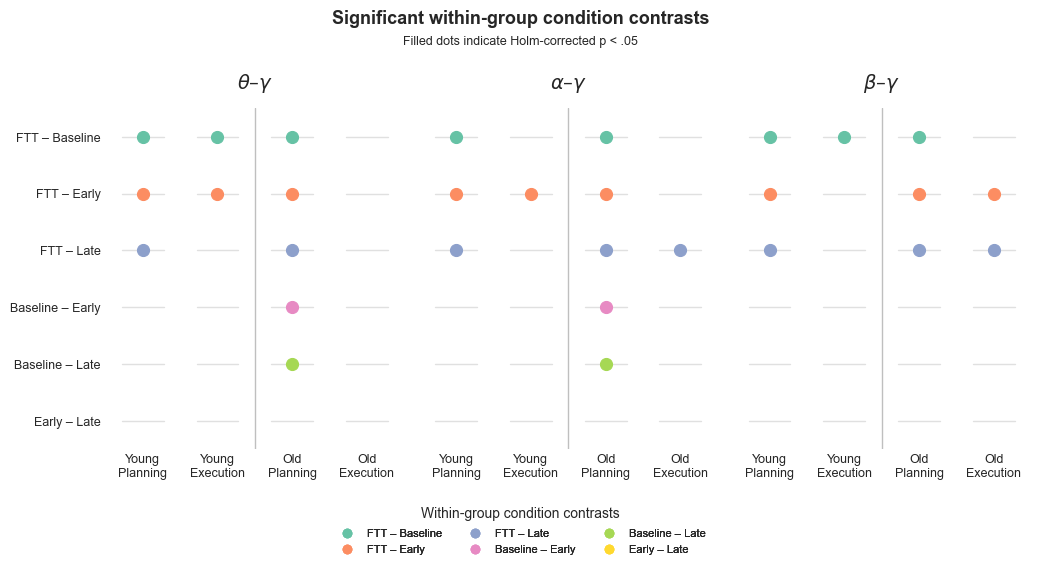

In [ ]:
# ── Paths ──────────────────────────────────────────────────────────────
LMM_DIR = Path(r"F:\# study 2\eeg_data\erpac\PCA\erpac_roi_tc\LMM")
FILE = LMM_DIR / "ERPAC_LMM_condition_contrasts_no_ROI.csv"
FIG_DIR = LMM_DIR / "figures_no_ROI"
FIG_DIR.mkdir(exist_ok=True)

# ── Settings ───────────────────────────────────────────────────────────
COUPLINGS = ["theta_gamma", "alpha_gamma", "beta_gamma"]

COUPLING_LABELS = {
    "theta_gamma": r"$\theta$–$\gamma$",
    "alpha_gamma": r"$\alpha$–$\gamma$",
    "beta_gamma": r"$\beta$–$\gamma$"
}

CONTRASTS = [
    "FTT - DeCRAT_baseline",
    "FTT - DeCRAT_adaptation_early",
    "FTT - DeCRAT_adaptation_late",
    "DeCRAT_baseline - DeCRAT_adaptation_early",
    "DeCRAT_baseline - DeCRAT_adaptation_late",
    "DeCRAT_adaptation_early - DeCRAT_adaptation_late",
]

CONTRAST_LABELS = [
    "FTT – Baseline",
    "FTT – Early",
    "FTT – Late",
    "Baseline – Early",
    "Baseline – Late",
    "Early – Late",
]

COLUMNS = [
    ("Y", "plan"),
    ("Y", "go"),
    ("O", "plan"),
    ("O", "go"),
]

COLUMN_LABELS = [
    "Young\nPlanning",
    "Young\nExecution",
    "Old\nPlanning",
    "Old\nExecution",
]

# ── Load data ──────────────────────────────────────────────────────────
df = pd.read_csv(FILE)

df["p.value"] = (
    df["p.value"]
    .astype(str)
    .str.replace("<", "", regex=False)
    .astype(float)
)

df["significant"] = df["p.value"] < 0.05

# ── Plot ───────────────────────────────────────────────────────────────
sns.set_theme(
    style="white",
    context="paper",
    font_scale=1.0
)

fig, axes = plt.subplots(
    1, 3,
    figsize=(10.5, 5.2),
    sharey=True
)

contrast_colors = sns.color_palette("Set2", n_colors=len(CONTRASTS))

for ax, coupling in zip(axes, COUPLINGS):

    d = df[df["coupling"] == coupling]

    for x, (group, stage) in enumerate(COLUMNS):

        for y, contrast in enumerate(CONTRASTS):

            match = d[
                (d["group"] == group) &
                (d["task_stage"] == stage) &
                (d["contrast"] == contrast)
            ]

            significant = (
                not match.empty and
                match.iloc[0]["significant"]
            )

            # Background guide
            ax.plot(
                [x - 0.28, x + 0.28],
                [y, y],
                color="0.88",
                linewidth=1,
                zorder=1
            )

            if significant:
                ax.scatter(
                    x,
                    y,
                    s=75,
                    color=contrast_colors[y],
                    zorder=3
                )

    # ── Formatting ────────────────────────────────────────────────────
    ax.set_title(
        COUPLING_LABELS[coupling],
        fontsize=14,
        fontweight="bold",
        pad=14
    )

    ax.set_xlim(-0.5, 3.5)
    ax.set_ylim(5.5, -0.5)

    ax.set_xticks(range(4))
    ax.set_xticklabels(
        COLUMN_LABELS,
        fontsize=9
    )

    ax.set_yticks(range(6))
    ax.set_yticklabels(
        CONTRAST_LABELS,
        fontsize=9
    )

    ax.tick_params(
        axis="both",
        length=0
    )

    # Separate Young / Old
    ax.axvline(
        1.5,
        color="0.75",
        linewidth=1
    )

    # Remove frame
    sns.despine(
        ax=ax,
        left=True,
        bottom=True
    )

    ax.set_xlabel("")
    ax.set_ylabel("")

    legend_handles = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="",
        markerfacecolor=contrast_colors[i],
        markeredgecolor="none",
        markersize=7,
        label=CONTRAST_LABELS[i].replace("\n", " ")
    )
    for i in range(len(CONTRASTS))
]

    fig.legend(
        handles=legend_handles,
        loc="lower center",
        ncol=3,
        frameon=False,
        fontsize=8,
        bbox_to_anchor=(0.5, -0.075)
    )

# ── Figure labels ──────────────────────────────────────────────────────
fig.text(
    0.5,
    0.015,
    "Within-group condition contrasts",
    ha="center",
    fontsize=10
)

fig.text(
    0.5,
    0.965,
    "Significant within-group condition contrasts",
    ha="center",
    fontsize=13,
    fontweight="bold"
)

fig.text(
    0.5,
    0.925,
    "Filled dots indicate Holm-corrected p < .05",
    ha="center",
    fontsize=9
)

plt.tight_layout(
    rect=[0, 0.06, 1, 0.90]
)

fig.savefig(
    FIG_DIR / "condition_contrast_significance_profile.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Available contrast types:
contrast_type
condition_within_stage    36
stage_within_condition    12
condition_within_group    12
group_within_condition     4
Name: count, dtype: int64[pyarrow]

Available contrast labels:
contrast
plan - go                                           12
FTT - DeCRAT_baseline                                8
FTT - DeCRAT_adaptation_early                        8
FTT - DeCRAT_adaptation_late                         8
DeCRAT_baseline - DeCRAT_adaptation_early            8
DeCRAT_baseline - DeCRAT_adaptation_late             8
DeCRAT_adaptation_early - DeCRAT_adaptation_late     8
Y - O                                                4
Name: count, dtype: int64[pyarrow]


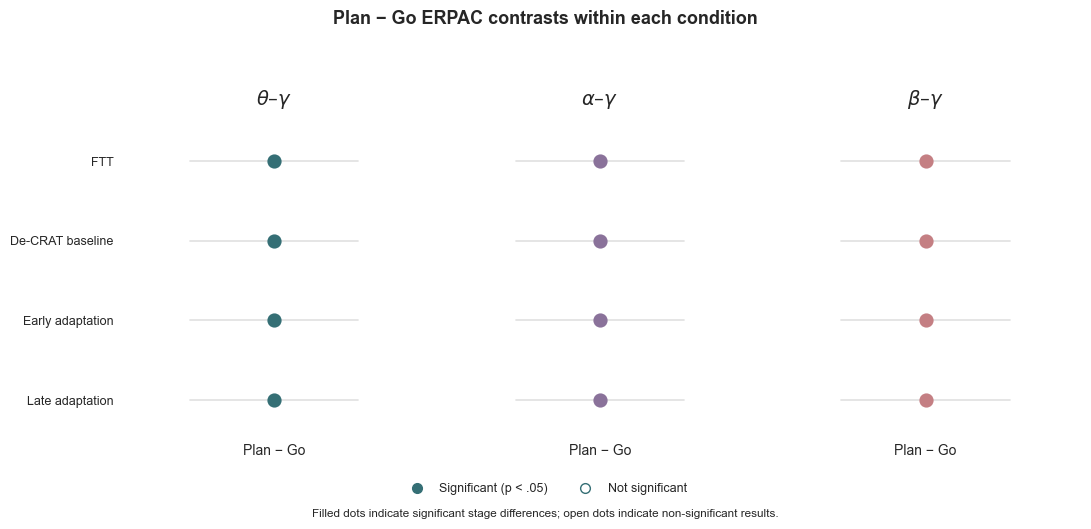

In [8]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D

# ── Paths ──────────────────────────────────────────────────────────────
LMM_DIR = Path(r"F:\# study 2\eeg_data\erpac\PCA\erpac_roi_tc\LMM")

# Use the CSV containing stage-within-condition post-hoc contrasts.
FILE = LMM_DIR / "S2_ERPAC_LMM_FINAL_UPD_posthocs_group_contrasts.csv"

FIG_DIR = LMM_DIR / "figures_no_ROI"
FIG_DIR.mkdir(exist_ok=True)

# ── Settings ───────────────────────────────────────────────────────────
COUPLINGS = ["theta_gamma", "alpha_gamma", "beta_gamma"]

COUPLING_LABELS = {
    "theta_gamma": r"$\theta$–$\gamma$",
    "alpha_gamma": r"$\alpha$–$\gamma$",
    "beta_gamma": r"$\beta$–$\gamma$",
}

CONDITIONS = [
    "FTT",
    "DeCRAT_baseline",
    "DeCRAT_adaptation_early",
    "DeCRAT_adaptation_late",
]

CONDITION_LABELS = [
    "FTT",
    "De-CRAT baseline",
    "Early adaptation",
    "Late adaptation",
]

GROUPS = ["Y", "O"]
GROUP_LABELS = ["Younger\nPlan − Go", "Older\nPlan − Go"]

ALPHA = 0.05

# Muted colours for the three coupling types
COUPLING_COLORS = {
    "theta_gamma": "#356F75",
    "alpha_gamma": "#8A729A",
    "beta_gamma": "#C47F83",
}

# ── Load data ──────────────────────────────────────────────────────────
df = pd.read_csv(FILE)

# Clean categorical columns
for col in ["coupling", "contrast_type", "group",
            "task_stage", "condition", "contrast"]:
    if col in df.columns:
        df[col] = df[col].astype("string").str.strip()

# Convert p-values, including values stored as strings
df["p.value"] = (
    df["p.value"]
    .astype(str)
    .str.replace("<", "", regex=False)
    .astype(float)
)

print("Available contrast types:")
print(df["contrast_type"].value_counts(dropna=False))

print("\nAvailable contrast labels:")
print(df["contrast"].value_counts(dropna=False))

# ── Identify Plan − Go comparisons ─────────────────────────────────────
# Adjust these aliases if your CSV uses different labels.
stage_types = {
    "stage_within_condition",
    "task_stage_within_condition",
    "stage",
    "task_stage",
}

d = df.copy()

# Keep only the relevant couplings and conditions.
# Do not filter by group, because these stage contrasts are pooled.
d = d[
    d["coupling"].isin(COUPLINGS)
    & d["condition"].isin(CONDITIONS)
].copy()

if d.empty:
    raise ValueError(
        "No Plan − Go contrasts found. Check contrast_type, "
        "contrast, coupling and condition labels."
    )

# Keep only the intended contrast type and Plan − Go comparison.
d["contrast_type_clean"] = (
    d["contrast_type"]
    .astype(str)
    .str.strip()
    .str.lower()
)

d["contrast_clean"] = (
    d["contrast"]
    .astype(str)
    .str.strip()
    .str.lower()
)

d = d[
    (d["contrast_type_clean"] == "stage_within_condition")
    & (d["contrast_clean"] == "plan - go")
].copy()

d["significant"] = d["p.value"] < ALPHA

# ── Plot ───────────────────────────────────────────────────────────────
sns.set_theme(style="white", context="paper", font_scale=1.0)

fig, axes = plt.subplots(
    1, 3,
    figsize=(11, 5.2),
    sharey=True
)

for ax, coupling in zip(axes, COUPLINGS):

    dc = d[d["coupling"] == coupling]

    x = 0  # Single column: pooled across age groups

    for y, condition in enumerate(CONDITIONS):

        match = dc[dc["condition"] == condition]

        # Background guide
        ax.plot(
            [x - 0.27, x + 0.27],
            [y, y],
            color="0.88",
            linewidth=1.2,
            zorder=1
        )

        # Filled dot = significant; open dot = not significant
        if match.empty:
            continue

        significant = bool(match.iloc[0]["significant"])

        ax.scatter(
            x,
            y,
            s=78,
            facecolor=(
                COUPLING_COLORS[coupling]
                if significant else "white"
            ),
            edgecolor=COUPLING_COLORS[coupling],
            linewidth=1.4,
            zorder=3
        )

    # Panel formatting
    ax.set_title(
        COUPLING_LABELS[coupling],
        fontsize=14,
        fontweight="bold",
        pad=12
    )

    ax.set_xlim(-0.5, 0.5)
    ax.set_ylim(3.5, -0.5)

    ax.set_xticks([0])
    ax.set_xticklabels(["Plan − Go"], fontsize=10)

    ax.set_yticks(range(len(CONDITIONS)))
    ax.set_yticklabels(CONDITION_LABELS, fontsize=9)

    ax.tick_params(axis="both", length=0)
    ax.grid(False)

    sns.despine(ax=ax, left=True, bottom=True)

    ax.set_xlabel("")
    ax.set_ylabel("")

# ── Legend ─────────────────────────────────────────────────────────────
legend_handles = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="",
        markerfacecolor="#356F75",
        markeredgecolor="#356F75",
        markersize=7,
        label="Significant (p < .05)"
    ),
    Line2D(
        [0], [0],
        marker="o",
        linestyle="",
        markerfacecolor="white",
        markeredgecolor="#356F75",
        markersize=7,
        label="Not significant"
    ),
]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    ncol=2,
    frameon=False,
    fontsize=9,
    bbox_to_anchor=(0.5, 0.025)
)

fig.suptitle(
    "Plan − Go ERPAC contrasts within each condition",
    fontsize=13,
    fontweight="bold",
    y=0.98
)

fig.text(
    0.5,
    0.005,
    "Filled dots indicate significant stage differences; "
    "open dots indicate non-significant results.",
    ha="center",
    fontsize=8.5
)

plt.tight_layout(rect=[0, 0.09, 1, 0.92])

# fig.savefig(
#     FIG_DIR / "stage_contrasts_within_condition_significance_matrix.png",
#     dpi=300,
#     bbox_inches="tight"
# )

# fig.savefig(
#     FIG_DIR / "stage_contrasts_within_condition_significance_matrix.pdf",
#     bbox_inches="tight"
# )

plt.show()

In [7]:
d

,coupling,contrast_type,group,task_stage,condition,contrast,estimate,SE,df,t.ratio,p.value,contrast_type_clean,contrast_clean,significant
12,theta_gamma,stage_within_condition,<NA>,<NA>,FTT,plan - go,-0.007347,0.001736,315.0,-4.232730,3.032199e-05,stage_within_condition,plan - go,True
13,theta_gamma,stage_within_condition,<NA>,<NA>,DeCRAT_baseline,plan - go,0.018150,0.001736,315.0,10.456584,3.647412e-22,stage_within_condition,plan - go,True
14,theta_gamma,stage_within_condition,<NA>,<NA>,DeCRAT_adaptation_early,plan - go,0.021347,0.001736,315.0,12.298716,1.172996e-28,stage_within_condition,plan - go,True
15,theta_gamma,stage_within_condition,<NA>,<NA>,DeCRAT_adaptation_late,plan - go,0.025712,0.001736,315.0,14.813307,4.834771e-38,stage_within_condition,plan - go,True
44,alpha_gamma,stage_within_condition,<NA>,<NA>,FTT,plan - go,-0.006022,0.001891,315.0,-3.185111,1.591810e-03,stage_within_condition,plan - go,True
45,alpha_gamma,stage_within_condition,<NA>,<NA>,DeCRAT_baseline,plan - go,0.021169,0.001891,315.0,11.196656,1.012190e-24,stage_within_condition,plan - go,True
46,alpha_gamma,stage_within_condition,<NA>,<NA>,DeCRAT_adaptation_early,plan - go,0.024670,0.001891,315.0,13.048030,2.096841e-31,stage_within_condition,plan - go,True
47,alpha_gamma,stage_within_condition,<NA>,<NA>,DeCRAT_adaptation_late,plan - go,0.024938,0.001891,315.0,13.190156,6.236251e-32,stage_within_condition,plan - go,True
60,beta_gamma,stage_within_condition,<NA>,<NA>,FTT,plan - go,-0.005030,0.001653,315.0,-3.041959,2.548040e-03,stage_within_condition,plan - go,True
61,beta_gamma,stage_within_condition,<NA>,<NA>,DeCRAT_baseline,plan - go,0.022017,0.001653,315.0,13.316190,2.121234e-32,stage_within_condition,plan - go,True


_________________________________

# ARCHIVED PLOTS

**VIOLINS**

In [ ]:
# ============================================================
# VIOLIN FIGURE
# GROUP × CONDITION — ALL COUPLINGS
#
# Layout:
# - planning / execution in separate panels
# - half violin = subject-level distribution
# - individual subject points on opposite half
# - EMM + 95% CI overlaid
# - significant Young vs Old contrasts within condition
# - significant condition contrasts within group
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator
from matplotlib.ticker import FixedLocator
from matplotlib.patches import Patch

# ============================================================
# PATHS
# ============================================================

LMM_DIR = Path(r"F:\# study 2\eeg_data\erpac\PCA\erpac_roi_tc\LMM")

EMM_FILE = LMM_DIR / "ERPAC_LMM_emmeans_for_plotting_no_ROI.csv"
GROUP_CONTRAST_FILE = LMM_DIR / "ERPAC_LMM_group_contrasts_no_ROI.csv"
STAGE_CONTRAST_FILE = LMM_DIR / "ERPAC_LMM_stage_contrasts_no_ROI.csv"
CONDITION_CONTRAST_FILE = LMM_DIR / "ERPAC_LMM_condition_contrasts_no_ROI.csv"

FIG_DIR = LMM_DIR / "figures_no_ROI"
FIG_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# SETTINGS
# ============================================================

COUPLING_ORDER = ["theta_gamma", "alpha_gamma", "beta_gamma"]

CONDITION_ORDER = [
    "FTT",
    "DeCRAT_baseline",
    "DeCRAT_adaptation_early",
    "DeCRAT_adaptation_late",
]

STAGE_ORDER = ["plan", "go"]
GROUP_ORDER = ["Y", "O"]

CONDITION_LABELS = {
    "FTT": "FTT",
    "DeCRAT_baseline": "Baseline",
    "DeCRAT_adaptation_early": "Early\nadaptation",
    "DeCRAT_adaptation_late": "Late\nadaptation",
}

STAGE_LABELS = {"plan": "Planning", "go": "Execution"}
GROUP_LABELS = {"Y": "Young", "O": "Old"}

COUPLING_LABELS = {
    "theta_gamma": r"$\theta$–$\gamma$ ERPAC",
    "alpha_gamma": r"$\alpha$–$\gamma$ ERPAC",
    "beta_gamma": r"$\beta$–$\gamma$ ERPAC",
}

# Explicitly chosen for presentation clarity.
STAGE_COLORS = {"plan": "#2A6F97", "go": "#D97706"}
GROUP_COLORS = {"Y": "#2F80ED", "O": "#C44E52"}

DPI = 300

# ============================================================
# LOAD DATA
# ============================================================

emm = pd.read_csv(EMM_FILE)
contrasts = pd.read_csv(GROUP_CONTRAST_FILE)

VALUE_COL = "mean_erpac"      
SUB_COL = "sub"

# Horizontal offsets of Young / Old within each condition
GROUP_OFFSET = {
    "Y": -0.18,
    "O":  0.18,
}

VIOLIN_WIDTH = 0.30
POINT_JITTER = 0.055
POINT_SIZE = 22
EMM_SIZE = 55


# ------------------------------------------------------------
# HALF-VIOLIN HELPER
# ------------------------------------------------------------

def add_half_violin(
    ax,
    values,
    position,
    color,
    width=0.30,
    side="left",
    alpha=0.30,
):

    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]

    if len(values) < 2:
        return

    vp = ax.violinplot(
        [values],
        positions=[position],
        widths=width,
        showmeans=False,
        showmedians=False,
        showextrema=False,
    )

    body = vp["bodies"][0]
    body.set_facecolor(color)
    body.set_edgecolor(color)
    body.set_alpha(alpha)

    # Clip violin to one side of its centre.
    path = body.get_paths()[0]
    vertices = path.vertices

    if side == "left":
        vertices[:, 0] = np.minimum(vertices[:, 0], position)
    else:
        vertices[:, 0] = np.maximum(vertices[:, 0], position)


# ------------------------------------------------------------
# INDIVIDUAL POINTS
# ------------------------------------------------------------

def add_individual_points(
    ax,
    values,
    position,
    color,
    side="right",
    jitter=0.055,
):

    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]

    if len(values) == 0:
        return

    rng = np.random.default_rng(12345)

    # Put points on the opposite side from the violin.
    if side == "right":
        xj = position + rng.uniform(0.025, jitter + 0.025, len(values))
    else:
        xj = position - rng.uniform(0.025, jitter + 0.025, len(values))

    ax.scatter(
        xj,
        values,
        s=POINT_SIZE,
        facecolor=color,
        edgecolor="white",
        linewidth=0.5,
        alpha=0.70,
        zorder=4,
    )


# ------------------------------------------------------------
# CONDITION CONTRAST LOOKUP
#
# Assumes you have a dataframe containing Holm-corrected
# condition contrasts, e.g.
#
# condition_contrasts columns:
# coupling, task_stage, group,
# condition_1, condition_2, p_holm
#
# Rename columns below if yours differ.
# ------------------------------------------------------------

def get_group_p(coupling, stage, condition):

    d = contrasts[
        (contrasts["coupling"] == coupling) &
        (contrasts["task_stage"] == stage) &
        (contrasts["condition"] == condition)
    ]

    if d.empty:
        return np.nan

    return d.iloc[0]["p.value"]


# ============================================================
# MAIN LOOP
# ============================================================

for coupling in emm["coupling"].dropna().unique():

    df_emm = emm[emm["coupling"] == coupling].copy()
    df_raw = RAW_DF[RAW_DF["coupling"] == coupling].copy()

    if df_emm.empty or df_raw.empty:
        continue

    fig, axes = plt.subplots(
        1,
        len(STAGE_ORDER),
        figsize=(13.5, 5.8),
        sharey=True,
        constrained_layout=True,
    )

    axes = np.atleast_1d(axes)

    # --------------------------------------------------------
    # Global Y spacing based on subject-level data + CIs
    # --------------------------------------------------------

    raw_min = df_raw[VALUE_COL].min()
    raw_max = df_raw[VALUE_COL].max()

    emm_min = df_emm["lower_ci"].min()
    emm_max = df_emm["upper_ci"].max()

    y_min = np.nanmin([raw_min, emm_min])
    y_max = np.nanmax([raw_max, emm_max])

    yrange = y_max - y_min

    if not np.isfinite(yrange) or yrange == 0:
        yrange = 1

    pad = yrange * 0.08

    # ========================================================
    # STAGE PANELS
    # ========================================================

    for ax, stage in zip(axes, STAGE_ORDER):

        raw_s = df_raw[df_raw["task_stage"] == stage]
        emm_s = df_emm[df_emm["task_stage"] == stage]

        x = np.arange(len(CONDITION_ORDER))

        positions = {
            group: x + GROUP_OFFSET[group]
            for group in GROUP_ORDER
        }

        group_values = {}

        # ====================================================
        # GROUP DISTRIBUTIONS + EMM
        # ====================================================

        for group in GROUP_ORDER:

            group_values[group] = {}

            for i, condition in enumerate(CONDITION_ORDER):

                centre = positions[group][i]

                # --------------------------------------------
                # Subject-level observations
                # --------------------------------------------

                d_raw = raw_s[
                    (raw_s["group"] == group) &
                    (raw_s["condition"] == condition)
                ]

                values = d_raw[VALUE_COL].dropna().to_numpy()

                # Young and Old both use inward-facing violins:
                #
                # Y: violin left, points right
                # O: violin left, points right
                #
                # This produces a consistent raincloud appearance.
                add_half_violin(
                    ax,
                    values,
                    position=centre,
                    color=GROUP_COLORS[group],
                    width=VIOLIN_WIDTH,
                    side="left",
                    alpha=0.28,
                )

                add_individual_points(
                    ax,
                    values,
                    position=centre,
                    color=GROUP_COLORS[group],
                    side="right",
                    jitter=POINT_JITTER,
                )

                # --------------------------------------------
                # EMM + confidence interval
                # --------------------------------------------

                d_emm = (
                    emm_s[
                        (emm_s["group"] == group) &
                        (emm_s["condition"] == condition)
                    ]
                )

                if d_emm.empty:
                    continue

                row = d_emm.iloc[0]

                mean = row["emmean"]
                low = row["lower_ci"]
                high = row["upper_ci"]

                group_values[group][condition] = {
                    "mean": mean,
                    "low": low,
                    "high": high,
                }

                ax.errorbar(
                    centre,
                    mean,
                    yerr=np.array([
                        [mean - low],
                        [high - mean],
                    ]),
                    fmt="none",
                    ecolor=GROUP_COLORS[group],
                    elinewidth=1.6,
                    capsize=4,
                    zorder=6,
                )

                ax.scatter(
                    centre,
                    mean,
                    s=EMM_SIZE,
                    facecolor="white",
                    edgecolor=GROUP_COLORS[group],
                    linewidth=2.0,
                    zorder=7,
                )

        # ====================================================
        # GROUP CONTRASTS:
        # YOUNG VS OLD WITHIN EACH CONDITION
        # ====================================================

        bracket_level = 0

        for i, condition in enumerate(CONDITION_ORDER):

            p = get_group_p(
                coupling,
                stage,
                condition,
            )

            stars = p_to_stars(p)

            if not stars:
                continue

            available_highs = []

            for group in GROUP_ORDER:
                if condition in group_values[group]:
                    available_highs.append(
                        group_values[group][condition]["high"]
                    )

            if not available_highs:
                continue

            y_bracket = (
                max(available_highs)
                + pad * 0.35
                + bracket_level * pad * 0.35
            )

            add_sig_bracket(
                ax,
                positions["Y"][i],
                positions["O"][i],
                y_bracket,
                stars,
                height=pad * 0.18,
            )

            bracket_level += 1

        # ====================================================
        # FORMATTING
        # ====================================================

        ax.set_title(
            STAGE_LABELS[stage],
            fontsize=14,
            fontweight="semibold",
            pad=12,
        )

        ax.set_xticks(x)
        ax.set_xticklabels(
            [
                CONDITION_LABELS[c]
                for c in CONDITION_ORDER
            ],
            fontsize=10,
        )

        ax.set_xlabel(
            "Condition",
            fontsize=11,
        )

        ax.set_ylabel(
            "ERPAC",
            fontsize=11,
        )

        style_axes(
            ax,
            grid_axis="y",
        )

    # ========================================================
    # LEGEND
    # ========================================================

    legend_handles = [
        Patch(
            facecolor=GROUP_COLORS[g],
            edgecolor=GROUP_COLORS[g],
            alpha=0.35,
            label=GROUP_LABELS[g],
        )
        for g in GROUP_ORDER
    ]

    axes[-1].legend(
        handles=legend_handles,
        frameon=False,
        fontsize=10,
        loc="best",
    )

    # ========================================================
    # COUPLING TITLE
    # ========================================================

    coupling_titles = {
        "theta_gamma": r"$\theta$–$\gamma$",
        "alpha_gamma": r"$\alpha$–$\gamma$",
        "beta_gamma": r"$\beta$–$\gamma$",
    }

    coupling_title = coupling_titles.get(
        coupling,
        coupling.replace("_", "–"),
    )

    fig.suptitle(
        f"{coupling_title} ERPAC — Young vs Old across conditions",
        fontsize=16,
        fontweight="bold",
    )

    # Leave enough vertical room for significance brackets.
    for ax in axes:
        current_bottom, current_top = ax.get_ylim()

        ax.set_ylim(
            min(current_bottom, y_min - pad),
            max(
                current_top,
                y_max + pad * 5,
            ),
        )

    # ========================================================
    # SAVE
    # ========================================================

    fig.savefig(
        FIG_DIR / f"{coupling}_02_group_condition_violin_v1.png",
        dpi=DPI,
        bbox_inches="tight",
    )

    plt.close(fig)

In [ ]:
# ============================================================
# FIGURE TYPE 2
# GROUP × CONDITION — ALL COUPLINGS
#
# - Planning / execution in separate panels
# - Half violin = subject-level distribution
# - Individual data points on opposite half
# - Open circle = EMM
# - Error bar = 95% CI
# - Short significance brackets = Young vs Old
# - Runs automatically for all couplings
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator
from matplotlib.ticker import FixedLocator
from matplotlib.patches import Patch

# ============================================================
# DATA
# ============================================================

RAW_DF = pd.read_csv(LMM_DIR / "pca_erpac_LMM_all_tasks_ROI_averaged.csv")
VALUE_COL = "mean_erpac"

# ============================================================
# PATHS
# ============================================================

LMM_DIR = Path(r"F:\# study 2\eeg_data\erpac\PCA\erpac_roi_tc\LMM")

EMM_FILE = LMM_DIR / "ERPAC_LMM_emmeans_for_plotting_no_ROI.csv"
GROUP_CONTRAST_FILE = LMM_DIR / "ERPAC_LMM_group_contrasts_no_ROI.csv"

FIG_DIR = LMM_DIR / "figures_no_ROI"
FIG_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# SETTINGS
# ============================================================

COUPLING_ORDER = ["theta_gamma", "alpha_gamma", "beta_gamma"]

CONDITION_ORDER = [
    "FTT",
    "DeCRAT_baseline",
    "DeCRAT_adaptation_early",
    "DeCRAT_adaptation_late",
]

STAGE_ORDER = ["plan", "go"]
GROUP_ORDER = ["Y", "O"]

CONDITION_LABELS = {
    "FTT": "FTT",
    "DeCRAT_baseline": "Baseline",
    "DeCRAT_adaptation_early": "Early\nadaptation",
    "DeCRAT_adaptation_late": "Late\nadaptation",
}

STAGE_LABELS = {"plan": "Planning", "go": "Execution"}
GROUP_LABELS = {"Y": "Young", "O": "Old"}

COUPLING_LABELS = {
    "theta_gamma": r"$\theta$–$\gamma$ ERPAC",
    "alpha_gamma": r"$\alpha$–$\gamma$ ERPAC",
    "beta_gamma": r"$\beta$–$\gamma$ ERPAC",
}

# Explicitly chosen for presentation clarity.
STAGE_COLORS = {"plan": "#2A6F97", "go": "#D97706"}
GROUP_COLORS = {"Y": "#2F80ED", "O": "#C44E52"}

DPI = 300

# ============================================================
# LOAD DATA
# ============================================================

emm = pd.read_csv(EMM_FILE)
contrasts = pd.read_csv(GROUP_CONTRAST_FILE)

VALUE_COL = "mean_erpac"      
SUB_COL = "sub"

# Your current "condition_contrasts" dataframe is actually
# the Young-vs-Old contrast within each condition.
group_contrasts = contrasts.copy()


# ============================================================
# PLOT SETTINGS
# ============================================================

GROUP_OFFSET = {
    "Y": -0.18,
    "O":  0.18,
}

VIOLIN_WIDTH = 0.28
POINT_JITTER = 0.060
POINT_SIZE = 24
EMM_SIZE = 65


# ============================================================
# OPTIONAL CHECK
#
# Make sure there is only one subject-level value for every
# plotted combination.
# ============================================================

check = (
    RAW_DF
    .groupby(
        [
            "sub",
            "group",
            "coupling",
            "task_stage",
            "condition",
        ]
    )
    .size()
)

if check.max() > 1:
    print(
        "WARNING: Some subjects have more than one value "
        "per group × coupling × stage × condition."
    )

    print(
        check[check > 1]
        .sort_values(ascending=False)
        .head(20)
    )


# ============================================================
# MAIN LOOP — ALL COUPLINGS
# ============================================================

for coupling in emm["coupling"].dropna().unique():

    df_emm = emm[
        emm["coupling"] == coupling
    ].copy()

    df_raw = RAW_DF[
        RAW_DF["coupling"] == coupling
    ].copy()

    if df_emm.empty or df_raw.empty:
        continue

    # --------------------------------------------------------
    # Determine plotting limits for this coupling.
    # --------------------------------------------------------

    raw_min = df_raw[VALUE_COL].min()
    raw_max = df_raw[VALUE_COL].max()

    ci_min = df_emm["lower_ci"].min()
    ci_max = df_emm["upper_ci"].max()

    y_min = np.nanmin([
        raw_min,
        ci_min,
    ])

    y_max = np.nanmax([
        raw_max,
        ci_max,
    ])

    yrange = y_max - y_min

    if not np.isfinite(yrange) or yrange == 0:
        yrange = 1

    pad = yrange * 0.08


    # ========================================================
    # FIGURE
    # ========================================================

    fig, axes = plt.subplots(
        1,
        len(STAGE_ORDER),
        figsize=(13.5, 5.8),
        sharey=True,
        constrained_layout=True,
    )

    axes = np.atleast_1d(axes)


    # ========================================================
    # STAGE PANELS
    # ========================================================

    for ax, stage in zip(
        axes,
        STAGE_ORDER,
    ):

        df_raw_stage = df_raw[
            df_raw["task_stage"] == stage
        ]

        df_emm_stage = df_emm[
            df_emm["task_stage"] == stage
        ]

        x = np.arange(
            len(CONDITION_ORDER)
        )

        positions = {
            group: x + GROUP_OFFSET[group]
            for group in GROUP_ORDER
        }

        emm_values = {
            group: {}
            for group in GROUP_ORDER
        }


        # ====================================================
        # DISTRIBUTIONS + EMM
        # ====================================================

        for group in GROUP_ORDER:

            for i, condition in enumerate(
                CONDITION_ORDER
            ):

                pos = positions[group][i]


                # ------------------------------------------------
                # Raw subject-level data
                # ------------------------------------------------

                d_raw = df_raw_stage[
                    (df_raw_stage["group"] == group) &
                    (
                        df_raw_stage["condition"]
                        == condition
                    )
                ]

                values = (
                    d_raw[VALUE_COL]
                    .dropna()
                    .to_numpy()
                )


                # ------------------------------------------------
                # Violin
                #
                # Violin extends toward the outside of each
                # Young/Old pair; dots extend toward the centre.
                # ------------------------------------------------

                if group == "Y":

                    violin_side = "left"
                    point_side = "right"

                else:

                    violin_side = "right"
                    point_side = "left"


                add_half_violin(
                    ax,
                    values,
                    position=pos,
                    color=GROUP_COLORS[group],
                    side=violin_side,
                    width=VIOLIN_WIDTH,
                    alpha=0.28,
                )

                add_individual_points(
                    ax,
                    values,
                    position=pos,
                    color=GROUP_COLORS[group],
                    side=point_side,
                    jitter=POINT_JITTER,
                )


                # ------------------------------------------------
                # EMM + confidence interval
                # ------------------------------------------------

                d_emm = df_emm_stage[
                    (df_emm_stage["group"] == group) &
                    (
                        df_emm_stage["condition"]
                        == condition
                    )
                ]

                if d_emm.empty:
                    continue

                row = d_emm.iloc[0]

                mean = row["emmean"]
                low = row["lower_ci"]
                high = row["upper_ci"]

                emm_values[group][condition] = {
                    "mean": mean,
                    "low": low,
                    "high": high,
                }


                # Confidence interval
                ax.errorbar(
                    pos,
                    mean,
                    yerr=np.array([
                        [mean - low],
                        [high - mean],
                    ]),
                    fmt="none",
                    ecolor=GROUP_COLORS[group],
                    elinewidth=1.5,
                    capsize=4,
                    capthick=1.2,
                    zorder=6,
                )


                # Open circle = EMM
                ax.scatter(
                    pos,
                    mean,
                    s=EMM_SIZE,
                    facecolor="white",
                    edgecolor=GROUP_COLORS[group],
                    linewidth=2.0,
                    zorder=7,
                )


        # ====================================================
        # YOUNG VS OLD SIGNIFICANCE
        #
        # Short bracket directly above each condition.
        # ====================================================

        for i, condition in enumerate(
            CONDITION_ORDER
        ):

            p = get_group_p(
                coupling,
                stage,
                condition,
            )

            stars = p_to_stars(p)

            # Only display statistically significant contrasts.
            if not stars:
                continue

            if (
                condition not in emm_values["Y"]
                or
                condition not in emm_values["O"]
            ):
                continue


            # Find the highest point of raw data / CI.
            raw_condition = df_raw_stage[
                df_raw_stage["condition"]
                == condition
            ][VALUE_COL]

            raw_top = (
                raw_condition.max()
                if not raw_condition.empty
                else -np.inf
            )

            ci_top = max(
                emm_values["Y"][condition]["high"],
                emm_values["O"][condition]["high"],
            )

            y_bracket = max(
                raw_top,
                ci_top,
            ) + pad * 0.30


            add_sig_bracket(
                ax,
                positions["Y"][i],
                positions["O"][i],
                y_bracket,
                stars,
                height=pad * 0.18,
            )


        # ====================================================
        # PANEL FORMATTING
        # ====================================================

        ax.set_title(
            STAGE_LABELS[stage],
            fontsize=14,
            fontweight="semibold",
            pad=12,
        )

        ax.set_xticks(x)

        ax.set_xticklabels(
            [
                CONDITION_LABELS[c]
                for c in CONDITION_ORDER
            ],
            fontsize=10,
        )

        ax.set_xlabel(
            "Condition",
            fontsize=11,
        )

        ax.set_ylabel(
            "ERPAC",
            fontsize=11,
        )

        style_axes(
            ax,
            grid_axis="y",
        )


        # Give brackets a little extra room.
        ax.set_ylim(
            y_min - pad * 0.5,
            y_max + pad * 1.8,
        )


    # ========================================================
    # LEGEND
    # ========================================================

    legend_handles = [
        Patch(
            facecolor=GROUP_COLORS[group],
            edgecolor=GROUP_COLORS[group],
            alpha=0.30,
            label=GROUP_LABELS[group],
        )
        for group in GROUP_ORDER
    ]

    axes[-1].legend(
        handles=legend_handles,
        frameon=False,
        fontsize=10,
        loc="best",
    )


    # ========================================================
    # COUPLING TITLE
    # ========================================================

    COUPLING_LABELS = {
        "theta_gamma": r"$\theta$–$\gamma$",
        "alpha_gamma": r"$\alpha$–$\gamma$",
        "beta_gamma": r"$\beta$–$\gamma$",
    }

    coupling_label = COUPLING_LABELS.get(
        coupling,
        coupling.replace("_", "–"),
    )

    fig.suptitle(
        f"{coupling_label} ERPAC — Young vs Old across conditions",
        fontsize=16,
        fontweight="bold",
    )


    # ========================================================
    # SAVE
    # ========================================================

    fig.savefig(
        FIG_DIR
        / f"{coupling}_02_group_condition_violin_v2.png",
        dpi=DPI,
        bbox_inches="tight",
    )

    plt.close(fig)

**FOREST**

In [ ]:
# ============================================================
# BEAUTIFIED PLOTTING OF ROI-AVERAGED ERPAC LMM RESULTS
#
# Figure 1: Stage × Condition interaction plots
# Figure 2: Theta-gamma Young vs Old comparison plots
# Figure 3: Young–Old forest plots
#
# Significant Young–Old contrasts are taken from the actual
# Holm-corrected contrast CSV produced by the R analysis.
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator
from matplotlib.ticker import FixedLocator


# ============================================================
# PATHS
# ============================================================

LMM_DIR = Path(r"F:\# study 2\eeg_data\erpac\PCA\erpac_roi_tc\LMM")

EMM_FILE = LMM_DIR / "ERPAC_LMM_emmeans_for_plotting_no_ROI.csv"
GROUP_CONTRAST_FILE = LMM_DIR / "ERPAC_LMM_group_contrasts_no_ROI.csv"
STAGE_CONTRAST_FILE = LMM_DIR / "ERPAC_LMM_stage_contrasts_no_ROI.csv"
CONDITION_CONTRAST_FILE = LMM_DIR / "ERPAC_LMM_condition_contrasts_no_ROI.csv"

FIG_DIR = LMM_DIR / "figures_no_ROI"
FIG_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# SETTINGS
# ============================================================

COUPLING_ORDER = ["theta_gamma", "alpha_gamma", "beta_gamma"]

CONDITION_ORDER = [
    "FTT",
    "DeCRAT_baseline",
    "DeCRAT_adaptation_early",
    "DeCRAT_adaptation_late",
]

STAGE_ORDER = ["plan", "go"]
GROUP_ORDER = ["Y", "O"]

CONDITION_LABELS = {
    "FTT": "FTT",
    "DeCRAT_baseline": "Baseline",
    "DeCRAT_adaptation_early": "Early\nadaptation",
    "DeCRAT_adaptation_late": "Late\nadaptation",
}

STAGE_LABELS = {"plan": "Planning", "go": "Execution"}
GROUP_LABELS = {"Y": "Young", "O": "Old"}

COUPLING_LABELS = {
    "theta_gamma": r"$\theta$–$\gamma$ ERPAC",
    "alpha_gamma": r"$\alpha$–$\gamma$ ERPAC",
    "beta_gamma": r"$\beta$–$\gamma$ ERPAC",
}

# Explicitly chosen for presentation clarity.
STAGE_COLORS = {"plan": "#2A6F97", "go": "#D97706"}
GROUP_COLORS = {"Y": "#2F80ED", "O": "#C44E52"}

DPI = 300


# ============================================================
# LOAD DATA
# ============================================================

emm = pd.read_csv(EMM_FILE)
contrasts = pd.read_csv(GROUP_CONTRAST_FILE)

for col in ["coupling", "group", "task_stage", "condition"]:
    emm[col] = emm[col].astype(str)

for col in ["coupling", "task_stage", "condition"]:
    contrasts[col] = contrasts[col].astype(str)

if "p.value" not in contrasts.columns:
    raise ValueError("Expected 'p.value' column in group contrast CSV.")

if "lower_ci" not in emm.columns or "upper_ci" not in emm.columns:
    raise ValueError("EMM CSV must contain lower_ci and upper_ci columns.")


# ============================================================
# FIGURE TYPE 1
# STAGE × CONDITION INTERACTION PLOTS
#
# Style:
# - clean interaction plot
# - Young / Old in separate panels
# - Planning and Execution shown as distinct line styles/colors
# - subtle CI bands plus points/error bars
# ============================================================

for coupling in COUPLING_ORDER:

    df_c = emm[emm["coupling"] == coupling].copy()

    if df_c.empty:
        continue

    fig, axes = plt.subplots(
        1, 2,
        figsize=(13.5, 5.4),
        sharey=True,
        constrained_layout=True,
    )

    _, y_high, yrange, pad = get_y_padding(df_c, frac=0.07)

    for ax, group in zip(axes, GROUP_ORDER):

        df_g = df_c[df_c["group"] == group]
        x = np.arange(len(CONDITION_ORDER))

        for stage in STAGE_ORDER:

            d = (
                df_g[df_g["task_stage"] == stage]
                .set_index("condition")
                .reindex(CONDITION_ORDER)
                .reset_index()
            )

            y = d["emmean"].to_numpy()
            low = d["lower_ci"].to_numpy()
            high = d["upper_ci"].to_numpy()

            linestyle = "-" if stage == "plan" else "--"

            ax.plot(
                x,
                y,
                marker="o",
                markersize=7,
                linewidth=2.2,
                linestyle=linestyle,
                color=STAGE_COLORS[stage],
                label=STAGE_LABELS[stage],
                zorder=3,
            )

            ax.fill_between(
                x,
                low,
                high,
                color=STAGE_COLORS[stage],
                alpha=0.10,
                zorder=1,
            )

            ax.errorbar(
                x,
                y,
                yerr=np.vstack([y - low, high - y]),
                fmt="none",
                ecolor=STAGE_COLORS[stage],
                elinewidth=1.2,
                capsize=3,
                alpha=0.8,
                zorder=2,
            )

            # Mark significant Young–Old contrasts at the relevant
            # Stage × Condition point using a small star above the CI.
            for i, condition in enumerate(CONDITION_ORDER):
                p = get_group_p(coupling, stage, condition)
                stars = p_to_stars(p)

                if stars:
                    ax.text(
                        x[i],
                        high[i] + pad * 0.35,
                        stars,
                        ha="center",
                        va="bottom",
                        fontsize=11,
                        fontweight="bold",
                        color=STAGE_COLORS[stage],
                    )

        ax.set_title(
            GROUP_LABELS[group],
            fontsize=14,
            fontweight="semibold",
            pad=12,
        )

        ax.set_xticks(x)
        ax.set_xticklabels(
            [CONDITION_LABELS[c] for c in CONDITION_ORDER],
            fontsize=10,
        )

        ax.set_xlabel("Condition", fontsize=11)
        ax.set_ylabel("Estimated marginal mean ERPAC", fontsize=11)

        ax.legend(
            frameon=False,
            fontsize=10,
            loc="best",
        )

        style_axes(ax, grid_axis="y")

    fig.suptitle(
        f"{COUPLING_LABELS[coupling]} — Stage × Condition",
        fontsize=16,
        fontweight="bold",
    )

    fig.savefig(
        FIG_DIR / f"{coupling}_01_stage_condition_by_group.png",
        dpi=DPI,
        bbox_inches="tight",
    )

    plt.close(fig)


# ============================================================
# FIGURE TYPE 2
# THETA-GAMMA GROUP × CONDITION
#
# Style:
# - paired Young vs Old comparison
# - planning / execution in separate panels
# - offset group points
# - shared thin condition trajectory
# - significance brackets for actual Holm-corrected contrasts
# ============================================================

coupling = "theta_gamma"
df_theta = emm[emm["coupling"] == coupling].copy()

if not df_theta.empty:

    fig, axes = plt.subplots(
        1, 2,
        figsize=(13.5, 5.5),
        sharey=True,
        constrained_layout=True,
    )

    _, _, yrange, pad = get_y_padding(df_theta, frac=0.08)

    for ax, stage in zip(axes, STAGE_ORDER):

        df_s = df_theta[df_theta["task_stage"] == stage]
        x = np.arange(len(CONDITION_ORDER))

        positions = {"Y": x - 0.10, "O": x + 0.10}
        group_values = {}

        for group in GROUP_ORDER:

            d = (
                df_s[df_s["group"] == group]
                .set_index("condition")
                .reindex(CONDITION_ORDER)
                .reset_index()
            )

            y = d["emmean"].to_numpy()
            low = d["lower_ci"].to_numpy()
            high = d["upper_ci"].to_numpy()

            group_values[group] = {
                "mean": y,
                "low": low,
                "high": high,
            }

            ax.plot(
                positions[group],
                y,
                marker="o",
                markersize=8,
                linewidth=2.0,
                color=GROUP_COLORS[group],
                label=GROUP_LABELS[group],
                zorder=3,
            )

            ax.errorbar(
                positions[group],
                y,
                yerr=np.vstack([y - low, high - y]),
                fmt="none",
                ecolor=GROUP_COLORS[group],
                elinewidth=1.2,
                capsize=4,
                zorder=2,
            )

        # Thin paired connectors within each condition.
        for i in range(len(CONDITION_ORDER)):
            ax.plot(
                [positions["Y"][i], positions["O"][i]],
                [
                    group_values["Y"]["mean"][i],
                    group_values["O"]["mean"][i],
                ],
                linewidth=0.9,
                alpha=0.35,
                zorder=1,
            )

        # Holm-corrected Young vs Old significance.
        for i, condition in enumerate(CONDITION_ORDER):

            p = get_group_p(coupling, stage, condition)
            stars = p_to_stars(p)

            if not stars:
                continue

            y_top = max(
                group_values["Y"]["high"][i],
                group_values["O"]["high"][i],
            ) + pad * 0.25

            add_sig_bracket(
                ax,
                positions["Y"][i],
                positions["O"][i],
                y_top,
                stars,
                height=pad * 0.20,
            )

        ax.set_title(
            STAGE_LABELS[stage],
            fontsize=14,
            fontweight="semibold",
            pad=12,
        )

        ax.set_xticks(x)
        ax.set_xticklabels(
            [CONDITION_LABELS[c] for c in CONDITION_ORDER],
            fontsize=10,
        )

        ax.set_xlabel("Condition", fontsize=11)
        ax.set_ylabel("Estimated marginal mean ERPAC", fontsize=11)

        ax.legend(
            frameon=False,
            fontsize=10,
            loc="best",
        )

        style_axes(ax, grid_axis="y")

    fig.suptitle(
        r"$\theta$–$\gamma$ ERPAC — Young vs Old across conditions",
        fontsize=16,
        fontweight="bold",
    )

    fig.savefig(
        FIG_DIR / "theta_gamma_02_group_condition.png",
        dpi=DPI,
        bbox_inches="tight",
    )

    plt.close(fig)


# ============================================================
# FIGURE TYPE 3
# YOUNG – OLD FOREST PLOTS
#
# Style:
# - minimal effect-size plot
# - alternating row shading
# - zero-reference line
# - marker color indicates direction of effect
# - significant contrasts shown with larger filled markers
# ============================================================

for coupling in COUPLING_ORDER:

    df_c = contrasts[
        contrasts["coupling"] == coupling
    ].copy()

    if df_c.empty:
        continue

    # --------------------------------------------------------
    # Build plotting dataframe
    # --------------------------------------------------------

    rows = []

    for stage in STAGE_ORDER:
        for condition in CONDITION_ORDER:

            r = df_c[
                (df_c["task_stage"] == stage)
                & (df_c["condition"] == condition)
            ]

            if r.empty:
                continue

            r = r.iloc[0]

            estimate = float(r["estimate"])
            se = float(r["SE"])
            p = float(r["p.value"])

            rows.append({
                "stage": stage,
                "condition": condition,
                "label": (
                    f"{STAGE_LABELS[stage]}  |  "
                    f"{CONDITION_LABELS[condition].replace(chr(10), ' ')}"
                ),
                "estimate": estimate,
                "lower": estimate - 1.96 * se,
                "upper": estimate + 1.96 * se,
                "p": p,
                "significant": p < 0.05,
            })

    forest = pd.DataFrame(rows)

    if forest.empty:
        continue

    # One fixed y position per contrast
    y = np.arange(len(forest))

    # --------------------------------------------------------
    # Dynamic figure size
    # --------------------------------------------------------

    # Increase figure height automatically if more rows are present
    row_height = 0.62
    fig_height = max(
        6.7,
        len(forest) * row_height + 1.8,
    )

    fig, ax = plt.subplots(
        figsize=(10.5, fig_height)
    )

    # --------------------------------------------------------
    # Alternating row shading
    # --------------------------------------------------------

    for yi in y:

        if yi % 2 == 0:
            ax.axhspan(
                yi - 0.5,
                yi + 0.5,
                alpha=0.04,
                zorder=0,
            )

    # --------------------------------------------------------
    # Plot confidence intervals and estimates
    # --------------------------------------------------------

    for yi, (_, row) in enumerate(forest.iterrows()):

        direction_color = (
            GROUP_COLORS["Y"]
            if row["estimate"] > 0
            else GROUP_COLORS["O"]
        )

        marker_size = (
            9
            if row["significant"]
            else 6
        )

        marker_alpha = (
            1.0
            if row["significant"]
            else 0.70
        )

        # 95% CI
        ax.plot(
            [row["lower"], row["upper"]],
            [yi, yi],
            linewidth=1.6,
            color=direction_color,
            alpha=marker_alpha,
            zorder=2,
        )

        # Estimate
        ax.plot(
            row["estimate"],
            yi,
            marker="o",
            markersize=marker_size,
            color=direction_color,
            alpha=marker_alpha,
            linestyle="None",
            zorder=3,
        )

    # --------------------------------------------------------
    # Zero-reference line
    # --------------------------------------------------------

    ax.axvline(
        0,
        linestyle="--",
        linewidth=1.2,
        alpha=0.75,
        zorder=1,
    )

    # --------------------------------------------------------
    # Axis labels and title
    # --------------------------------------------------------

    ax.set_xlabel(
        "Young − Old estimated ERPAC difference",
        fontsize=11,
    )

    ax.set_title(
        f"{COUPLING_LABELS[coupling]} — Young vs Old effect estimates",
        fontsize=15,
        fontweight="bold",
        pad=12,
    )

    # --------------------------------------------------------
    # General axis styling
    #
    # IMPORTANT:
    # style_axes() is called BEFORE forcing the y-axis ticks.
    # This prevents style_axes() from removing every second label.
    # --------------------------------------------------------

    style_axes(
        ax,
        grid_axis=None,
    )

    # --------------------------------------------------------
    # FORCE ALL Y-AXIS LABELS
    # --------------------------------------------------------

    # Explicit fixed locator:
    # one tick for every row in the dataframe
    ax.yaxis.set_major_locator(
        FixedLocator(y)
    )

    ax.set_yticks(y)

    ax.set_yticklabels(
        forest["label"].tolist(),
        fontsize=10,
    )

    # Explicitly retain all labels
    ax.tick_params(
        axis="y",
        which="major",
        labelleft=True,
        length=0,
        pad=6,
    )

    # Reverse order so first condition appears at the top
    ax.set_ylim(
        len(forest) - 0.5,
        -0.5,
    )

    # --------------------------------------------------------
    # Significance labels
    # --------------------------------------------------------

    x_min = forest["lower"].min()
    x_max = forest["upper"].max()

    x_span = x_max - x_min

    if x_span == 0:
        x_span = 0.01

    significant_x = []

    for yi, (_, row) in enumerate(forest.iterrows()):

        stars = p_to_stars(
            row["p"]
        )

        if stars:

            text_x = (
                row["upper"]
                + 0.035 * x_span
            )

            significant_x.append(text_x)

            ax.text(
                text_x,
                yi,
                f"{stars}  p={row['p']:.3g}",
                va="center",
                ha="left",
                fontsize=10,
                fontweight="bold",
            )

    # --------------------------------------------------------
    # Give significance text enough horizontal space
    # --------------------------------------------------------

    plot_x_min = forest["lower"].min()
    plot_x_max = forest["upper"].max()

    if significant_x:
        plot_x_max = max(
            plot_x_max,
            max(significant_x)
            + 0.12 * x_span,
        )

    horizontal_pad = (
        0.08 * max(
            plot_x_max - plot_x_min,
            0.01,
        )
    )

    ax.set_xlim(
        plot_x_min - horizontal_pad,
        plot_x_max + horizontal_pad,
    )

    # --------------------------------------------------------
    # Legend
    # --------------------------------------------------------

    legend_elements = [
        Line2D(
            [0],
            [0],
            marker="o",
            linestyle="None",
            markersize=7,
            color=GROUP_COLORS["Y"],
            label="Young > Old",
        ),
        Line2D(
            [0],
            [0],
            marker="o",
            linestyle="None",
            markersize=7,
            color=GROUP_COLORS["O"],
            label="Old > Young",
        ),
    ]

    ax.legend(
        handles=legend_elements,
        frameon=False,
        fontsize=9,
        loc="lower right",
    )

    # --------------------------------------------------------
    # Layout
    # --------------------------------------------------------

    # More left-hand space for long condition names
    fig.subplots_adjust(
        left=0.31,
        right=0.96,
        top=0.91,
        bottom=0.10,
    )

    # --------------------------------------------------------
    # Save
    # --------------------------------------------------------

    fig.savefig(
        FIG_DIR
        / f"{coupling}_03_young_old_forest.png",
        dpi=DPI,
        bbox_inches="tight",
    )

    plt.close(fig)


# ============================================================
# FINISH
# ============================================================

print("Plotting complete.")
print(f"Beautified figures saved to:\n{FIG_DIR}")
